# Wavelength-Swap Ablation Ladder — Baseline vs. P1 vs. P2 vs. P3 vs. P4 vs. Const-WL

Tests whether wavelength-conditioned encoders (DOFA, DOFA+, Panopticon, Copernicus-FM, CARL, SMARTIES)
generate physically sensible weights through their hypernetwork / dynamic-projection mechanism, by
comparing six conditions on the **same frozen encoder** (`finetune=false`), UPerNet decoder. Pixel data
and normalization are untouched in every condition below -- only the wavelength/proj_idx label fed to the
hypernetwork changes.

| Condition | What changes | Severity |
|---|---|---|
| **Baseline (S2)** | Nothing -- regular benchmark, correct S2 wavelength labels | reference |
| **P1 (neighbor swap)** | 3 (or 1) band-label pairs swapped between *spectrally adjacent* bands (Δ23-43nm) | mild -- sanity floor |
| **P2 (within-group permutation)** | Full random reshuffle of labels *within* a spectral group (VIS / red-edge-NIR / SWIR), 2 seeded draws, never crossing group boundaries | medium |
| **P3 (full reversal)** | Deterministic index-reversal of the *entire* wavelength vector -- first band gets the last band's label and so on inward. One fixed config, no seeds | severe, structured |
| **P4 (full random shuffle)** | Unconstrained random permutation of the *entire* wavelength vector -- any band can get any other band's label, no group boundary. 3 seeded draws | severe, unstructured |
| **Const-WL (550 nm)** | *All* optical bands relabeled to a single uninformative wavelength | most severe -- destroys wavelength conditioning entirely |

**Expectation**: if the hypernetwork is physically grounded, damage should scale with perturbation severity
-- roughly `|Δ P1| <= |Δ P2| <= |Δ P3|, |Δ P4| <= |Δ Const-WL|`. P3 and P4 are not expected to have a fixed
order relative to each other (one is a specific structured reversal, the other unconstrained random chaos)
-- this notebook checks the ladder empirically rather than assuming it.

**P2 draws:** two independent seeded derangements (SEED_A=42, SEED_B=7); see `p2_wlswap_draws.json`.
**P4 draws:** three independent seeded derangements (SEED_1=101, SEED_2=202, SEED_3=303); see
`p4_wlswap_draws.json`. Both check draw-to-draw agreement below -- if draws disagree noticeably for some
encoder/dataset, that result is noisy and should be read with caution.

**Datasets / metrics:**

| Dataset | Task | Metric |
|---|---|---|
| MADOS | segmentation | mIoU |
| m-Cashew-Plantation | segmentation | mIoU |
| m-SA-Crop-Type | segmentation | mIoU |
| m-Forestnet | linear classification | Accuracy |

**Run sources:**
- Baseline (S2): `pangaea_full_seg/upernet/{enc}_seg/` (MADOS), `geobench/seg/UPerNet/{enc}/` (m-Cashew-Plantation, m-SA-Crop-Type), `geobench/cls/{enc}/` (m-Forestnet)
- P1: `p1_wlswap_ablation/{enc}/`
- P2: `p2_wlswap_ablation/{enc}_draw{A,B}/`
- P3: `p3_wlswap_ablation/{enc}/`
- P4: `p4_wlswap_ablation/{enc}_draw{1,2,3}/`
- Const-WL: `wavelength_ablation_const_wl/{short}_const_wl_up/` and `..._const_wl_cls/`

In [1]:
import re
from pathlib import Path
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")
Path("figures").mkdir(exist_ok=True)

# encoder_key -> (display_name, baseline_seg_subdir, baseline_cls_subdir, const_wl_short)
ENCODER_INFO = {
    "dofa":               ("DOFA",           "dofa_seg",               "dofa",               "dofa"),
    "dofav2":             ("DOFA+",         "dofav2_seg",             "dofav2",             "dofav2"),
    "panopticon":         ("Panopticon",     "panopticon_seg",         "panopticon",         "panopticon"),
    "copernicus_fm_base": ("Copernicus-FM",  "copernicus_fm_base_seg", "copernicus_fm_base", "cfm"),
    "carl":               ("CARL",           "carl_seg",               "carl",               "carl_dw"),
    "smarties_vitb":      ("SMARTIES",       "smarties_vitb_seg",      "smarties_vitb",      "sm"),
}
ENCODER_ORDER = ["DOFA", "DOFA+", "Panopticon", "Copernicus-FM", "CARL", "SMARTIES"]

# run-dir substring -> display name, for the three segmentation datasets
SEG_KEYS = [
    ("mados",               "MADOS"),
    ("mcashew-plantation",  "m-Cashew-Plantation"),
    ("msa-crop-type",       "m-SA-Crop-Type"),
]
ALL_DS_KEYS = SEG_KEYS + [("mforestnet", "m-Forestnet")]

DATASET_ORDER  = ["MADOS", "m-Cashew-Plantation", "m-SA-Crop-Type", "m-Forestnet"]
METRIC_LABELS  = {"MADOS": "mIoU", "m-Cashew-Plantation": "mIoU", "m-SA-Crop-Type": "mIoU", "m-Forestnet": "Accuracy"}

# Severity order (mild -> severe)
CONDITION_ORDER = [
    "Baseline (S2)", "P1 (neighbor swap)", "P2 (mean of 2 draws)",
    "P3 (full reversal)", "P4 (mean of 3 draws)", "Const-WL (550nm)",
]
PERTURBATIONS = CONDITION_ORDER[1:]  # everything except baseline, in severity order

_severity_cmap = cm.get_cmap("YlOrRd")
COND_COLORS = {
    "Baseline (S2)":         "#5B8DB8",
    "P1 (neighbor swap)":    mcolors.to_hex(_severity_cmap(0.30)),
    "P2 (mean of 2 draws)":  mcolors.to_hex(_severity_cmap(0.48)),
    "P3 (full reversal)":    mcolors.to_hex(_severity_cmap(0.66)),
    "P4 (mean of 3 draws)":  mcolors.to_hex(_severity_cmap(0.84)),
    "Const-WL (550nm)":      mcolors.to_hex(_severity_cmap(1.00)),
}

print("Config loaded.")

Config loaded.


/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_42199/3298617595.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _severity_cmap = cm.get_cmap("YlOrRd")


In [2]:
# ── Parse functions (same format as analyze_wavelength_ablation.ipynb) ──────

def parse_log_metrics(log_path: Path) -> dict:
    """Parse segmentation train.log-0 -- returns test_mIoU, test_mF1, etc."""
    log_path = Path(log_path)
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("IoU", "test_mIoU"), ("F1-score", "test_mF1"),
        ("Precision", "test_mPrecision"), ("Recall", "test_mRecall"),
    ]:
        m = re.search(rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def parse_cls_log_metrics(log_path: Path) -> dict:
    """Parse classification train.log-0 -- returns test_Accuracy, test_mF1, etc."""
    log_path = Path(log_path)
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- Accuracy", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- Accuracy" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("Accuracy", "test_Accuracy"), ("F1-score", "test_mF1"),
        ("Precision", "test_Precision"), ("Recall", "test_Recall"),
    ]:
        m = re.search(rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def parse_run(run_dir: Path, dataset_label: str):
    """Dispatch to the right parser based on dataset, return the primary metric or None."""
    if dataset_label == "m-Forestnet":
        m = parse_cls_log_metrics(run_dir / "train.log-0")
        return m.get("test_Accuracy")
    m = parse_log_metrics(run_dir / "train.log-0")
    return m.get("test_mIoU")

print("Parse functions defined.")

Parse functions defined.


## Load results

In [3]:
# ── Baseline (S2) ────────────────────────────────────────────────────────────

def load_baseline() -> pd.DataFrame:
    rows = []
    upernet_base = EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet"
    geobench_seg_base = EXPERIMENTS_BASE / "geobench" / "seg" / "UPerNet"
    geobench_cls_base = EXPERIMENTS_BASE / "geobench" / "cls"

    for enc_key, (enc_label, seg_subdir, cls_subdir, _) in ENCODER_INFO.items():
        # MADOS -- regular full-seg benchmark
        d = upernet_base / seg_subdir
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir() or "mados" not in run_dir.name:
                    continue
                val = parse_run(run_dir, "MADOS")
                if val is not None:
                    rows.append(dict(encoder=enc_label, dataset="MADOS", condition="Baseline (S2)",
                                      metric=val, run_dir=run_dir.name))

        # m-Cashew-Plantation, m-SA-Crop-Type -- GeoBench UPerNet
        d = geobench_seg_base / enc_key
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in SEG_KEYS[1:]:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition="Baseline (S2)",
                                              metric=val, run_dir=run_dir.name))

        # m-Forestnet -- GeoBench linear-probe classification
        d = geobench_cls_base / cls_subdir
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir() or "mforestnet" not in run_dir.name:
                    continue
                val = parse_run(run_dir, "m-Forestnet")
                if val is not None:
                    rows.append(dict(encoder=enc_label, dataset="m-Forestnet", condition="Baseline (S2)",
                                      metric=val, run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_baseline = load_baseline()
print(f"{len(df_baseline)} baseline results loaded")
df_baseline.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

25 baseline results loaded


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL,51.931,61.731,0.442,31.555
Copernicus-FM,56.897,69.898,0.519,34.043
DOFA,60.389,66.903,0.560,32.444
DOFA+,48.602,65.200,0.505,29.780
Panopticon,68.217,73.170,0.555,36.210
SMARTIES,62.282,71.056,0.506,32.695


In [4]:
# ── Const-WL (all optical bands forced to 550 nm) ───────────────────────────

def load_const_wl() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "wavelength_ablation_const_wl"
    for enc_key, (enc_label, _, _, short) in ENCODER_INFO.items():
        d = base / f"{short}_const_wl_up"
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in SEG_KEYS:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition="Const-WL (550nm)",
                                              metric=val, run_dir=run_dir.name))

        d = base / f"{short}_const_wl_cls"
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir() or "mforestnet" not in run_dir.name:
                    continue
                val = parse_run(run_dir, "m-Forestnet")
                if val is not None:
                    rows.append(dict(encoder=enc_label, dataset="m-Forestnet", condition="Const-WL (550nm)",
                                      metric=val, run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_const_wl = load_const_wl()
print(f"{len(df_const_wl)} const-WL results loaded")
df_const_wl.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

24 const-WL results loaded


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL,32.553,48.846,0.403,23.486
Copernicus-FM,42.635,65.104,0.512,29.584
DOFA,33.084,53.079,0.524,20.565
DOFA+,38.363,59.216,0.489,23.189
Panopticon,44.884,67.848,0.540,27.949
SMARTIES,25.005,44.670,0.414,18.576


In [5]:
# ── P1 (neighbor-band wavelength-label swap) ────────────────────────────────

def load_p1() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "p1_wlswap_ablation"
    for enc_key, (enc_label, _, _, _) in ENCODER_INFO.items():
        d = base / enc_key
        if not d.exists():
            continue
        for run_dir in sorted(d.iterdir()):
            if not run_dir.is_dir():
                continue
            for key, label in ALL_DS_KEYS:
                if key in run_dir.name:
                    val = parse_run(run_dir, label)
                    if val is not None:
                        rows.append(dict(encoder=enc_label, dataset=label, condition="P1 (neighbor swap)",
                                          metric=val, run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p1 = load_p1()
print(f"{len(df_p1)} P1 results loaded")
df_p1.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

24 P1 results loaded


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL,47.134,59.341,0.473,32.490
Copernicus-FM,57.811,69.967,0.522,33.055
DOFA,61.090,66.975,0.555,32.540
DOFA+,46.144,64.792,0.516,29.792
Panopticon,66.589,72.993,0.554,36.082
SMARTIES,61.563,70.554,0.491,33.032


In [6]:
# ── P2 (within-group random permutation, 2 seeded draws) ────────────────────

def load_p2_draws() -> pd.DataFrame:
    """Per-draw P2 results -- kept separate so we can check draw agreement below."""
    rows = []
    base = EXPERIMENTS_BASE / "p2_wlswap_ablation"
    for enc_key, (enc_label, _, _, _) in ENCODER_INFO.items():
        for draw in ["A", "B"]:
            d = base / f"{enc_key}_draw{draw}"
            if not d.exists():
                continue
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in ALL_DS_KEYS:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, draw=draw,
                                              metric=val, run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p2_draws = load_p2_draws()
print(f"{len(df_p2_draws)} P2 per-draw results loaded "
      f"({(df_p2_draws['draw'] == 'A').sum()} draw A, {(df_p2_draws['draw'] == 'B').sum()} draw B)")
df_p2_draws.pivot_table(index=["encoder", "dataset"], columns="draw", values="metric", aggfunc="max").round(3)

48 P2 per-draw results loaded (24 draw A, 24 draw B)


draw                                    A       B
encoder       dataset                            
CARL          MADOS                42.265  41.037
              m-Cashew-Plantation  55.847  58.094
              m-Forestnet           0.471   0.466
              m-SA-Crop-Type       31.129  31.964
Copernicus-FM MADOS                57.994  48.596
              m-Cashew-Plantation  68.090  68.284
              m-Forestnet           0.514   0.529
              m-SA-Crop-Type       32.068  32.159
DOFA          MADOS                58.408  58.798
              m-Cashew-Plantation  67.351  67.117
              m-Forestnet           0.563   0.565
              m-SA-Crop-Type       31.667  31.655
DOFA+         MADOS                46.723  48.062
              m-Cashew-Plantation  64.161  65.421
              m-Forestnet           0.512   0.519
              m-SA-Crop-Type       28.797  28.942
Panopticon    MADOS                62.912  62.683
              m-Cashew-Plantation  72.874  72.435
              m-Forestnet           0.568   0.545
              m-SA-Crop-Type       35.694  34.655
SMARTIES      MADOS                52.400  56.957
              m-Cashew-Plantation  68.868  68.700
              m-Forestnet           0.503   0.498
              m-SA-Crop-Type       32.926  32.902

### What actually got swapped in the two P2 draws

Slope chart: left column is each channel's *native* (correct) wavelength, right column is the wavelength
label it got reassigned to in that draw. Color = spectral group (never crosses group boundaries, by
construction). Gray dashed = held fixed (untouched). SWIR is a deterministic swap (only 2 members), so it
looks identical in both draws -- everything else is the seeded random derangement.
Source: `scripts/slurm_scripts/wavelength_ablation/p2_wlswap_draws.json`.

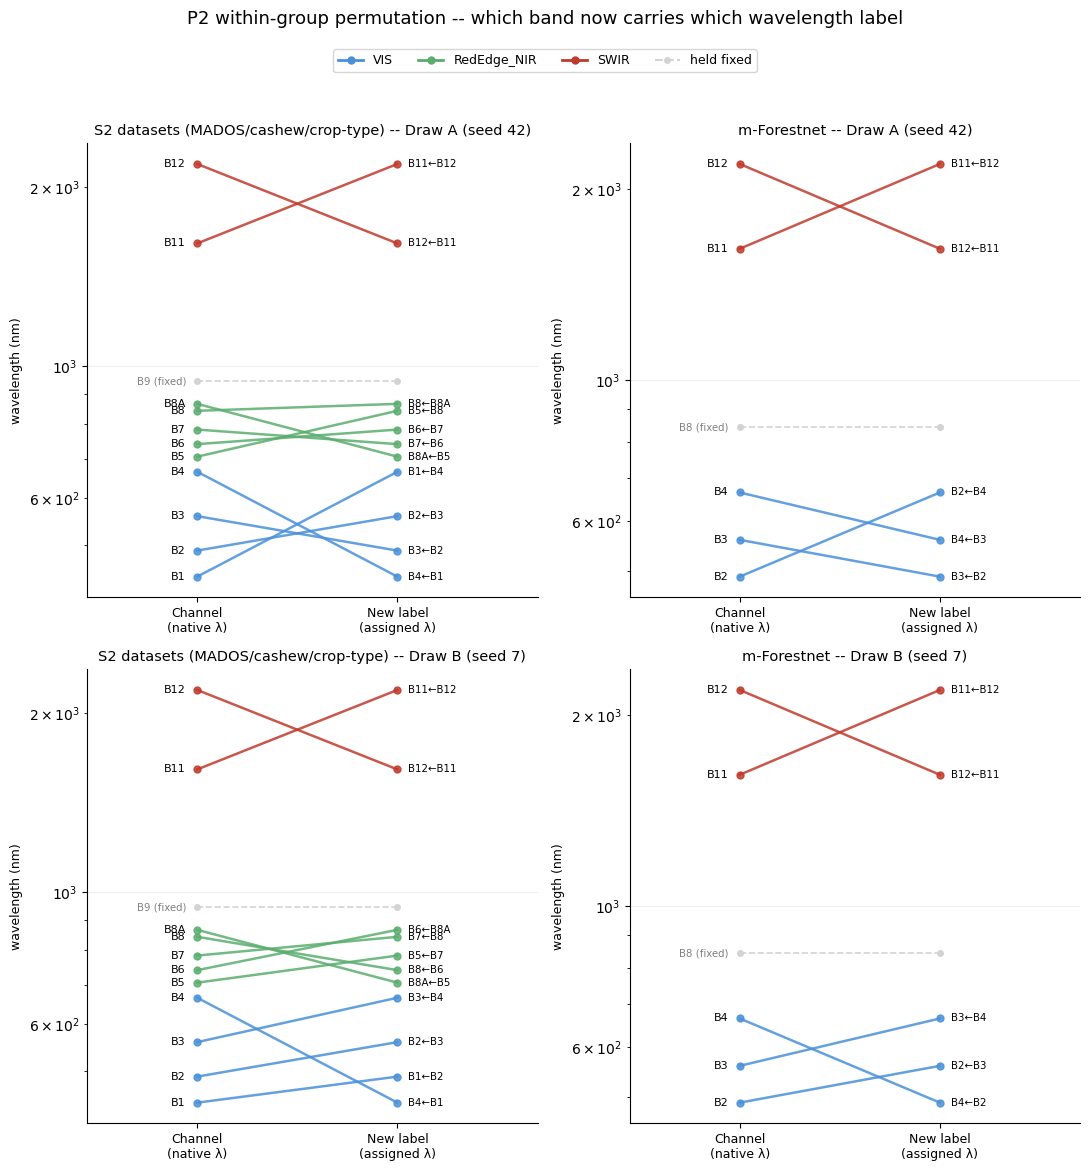

In [7]:
import json as _json

with open("../../scripts/slurm_scripts/wavelength_ablation/p2_wlswap_draws.json") as f:
    p2_manifest = _json.load(f)

# Canonical nm reference table for display only (matches Copernicus-FM's whole-number nm
# convention) -- the actual per-encoder values used in the runs differ slightly in unit/precision,
# see p2_manifest["resolved_values_by_encoder"] for those.
REF_WL_NM = {
    "B1": 443, "B2": 490, "B3": 560, "B4": 665, "B5": 705, "B6": 740, "B7": 783,
    "B8": 842, "B8A": 865, "B9": 945, "B10": 1375, "B11": 1610, "B12": 2190,
}

GROUP_COLORS = {
    "VIS": "#4A90D9",
    "RedEdge_NIR": "#5BAD6F",
    "mForestnet_RGB": "#4A90D9",
    "SWIR": "#C0392B",
}


def plot_permutation_panel(ax, dsgroup: str, draw: str, title: str):
    groups = p2_manifest["groups"]
    band_to_group = {}
    mapping = {}

    if dsgroup == "s2":
        for gname in ["VIS", "RedEdge_NIR"]:
            for b in groups[gname]["members"]:
                band_to_group[b] = gname
            mapping.update(groups[gname]["mapping"][draw])
        for b in groups["SWIR"]["members"]:
            band_to_group[b] = "SWIR"
        mapping.update(groups["SWIR"]["swap"])
        fixed_bands = ["B9"]
    else:
        for b in groups["mForestnet_RGB"]["members"]:
            band_to_group[b] = "mForestnet_RGB"
        mapping.update(groups["mForestnet_RGB"]["mapping"][draw])
        for b in groups["SWIR"]["members"]:
            band_to_group[b] = "SWIR"
        mapping.update(groups["SWIR"]["swap"])
        fixed_bands = ["B8"]

    for band, source in mapping.items():
        y0, y1 = REF_WL_NM[band], REF_WL_NM[source]
        color = GROUP_COLORS[band_to_group[band]]
        ax.plot([0, 1], [y0, y1], color=color, alpha=0.85, linewidth=1.8, marker="o", markersize=5, zorder=3)
        ax.annotate(band, (0, y0), textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=8)
        ax.annotate(f"{band}←{source}", (1, y1), textcoords="offset points", xytext=(8, 0),
                     ha="left", va="center", fontsize=7.3)

    for band in fixed_bands:
        y = REF_WL_NM[band]
        ax.plot([0, 1], [y, y], color="lightgray", linestyle="--", linewidth=1.2, marker="o",
                 markersize=4, zorder=1)
        ax.annotate(f"{band} (fixed)", (0, y), textcoords="offset points", xytext=(-8, 0),
                     ha="right", va="center", fontsize=7.3, color="gray")

    ax.set_yscale("log")
    ax.set_xlim(-0.55, 1.7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Channel\n(native λ)", "New label\n(assigned λ)"], fontsize=9)
    ax.set_ylabel("wavelength (nm)", fontsize=9)
    ax.set_title(title, fontsize=10.5)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(2, 2, figsize=(11, 11))
plot_permutation_panel(axes[0, 0], "s2",  "A", "S2 datasets (MADOS/cashew/crop-type) -- Draw A (seed 42)")
plot_permutation_panel(axes[0, 1], "mfn", "A", "m-Forestnet -- Draw A (seed 42)")
plot_permutation_panel(axes[1, 0], "s2",  "B", "S2 datasets (MADOS/cashew/crop-type) -- Draw B (seed 7)")
plot_permutation_panel(axes[1, 1], "mfn", "B", "m-Forestnet -- Draw B (seed 7)")

legend_handles = [plt.Line2D([0], [0], color=c, lw=2, marker="o", markersize=5, label=g)
                  for g, c in GROUP_COLORS.items() if g != "mForestnet_RGB"]
legend_handles.append(plt.Line2D([0], [0], color="lightgray", lw=1.5, linestyle="--", marker="o",
                                  markersize=4, label="held fixed"))
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=4, fontsize=9)

fig.suptitle("P2 within-group permutation -- which band now carries which wavelength label", fontsize=13, y=1.06)
fig.tight_layout()
fig.savefig("figures/p2_permutation_diagram.png", bbox_inches="tight", dpi=150)
fig.savefig("figures/p2_permutation_diagram.pdf", bbox_inches="tight")
plt.show()

### P2 draw agreement

The two draws are independent random within-group permutations. If they tell a consistent story (similar Δ
vs. baseline, same sign), the perturbation's effect is dominated by the *severity* of the manipulation, not
by which specific bands happened to swap -- exactly what we want for a reusable "severity rung" in the
ladder. If they disagree substantially for some encoder/dataset, that pair's P2 result is noisy and would
need a third draw (or the deterministic reversal tie-breaker, i.e. P3) before drawing conclusions from it.

,dataset,encoder,delta_draw_A,delta_draw_B,abs_disagreement,flag
4,MADOS,Copernicus-FM,1.097,-8.301,9.398,⚠️
20,MADOS,SMARTIES,-9.882,-5.325,4.557,✅
12,MADOS,DOFA+,-1.879,-0.540,1.339,⚠️
0,MADOS,CARL,-9.666,-10.894,1.228,✅
8,MADOS,DOFA,-1.981,-1.591,0.390,✅
16,MADOS,Panopticon,-5.305,-5.534,0.229,✅
1,m-Cashew-Plantation,CARL,-5.884,-3.637,2.247,✅
13,m-Cashew-Plantation,DOFA+,-1.039,0.221,1.260,⚠️
17,m-Cashew-Plantation,Panopticon,-0.296,-0.735,0.439,✅
9,m-Cashew-Plantation,DOFA,0.448,0.214,0.234,✅



8/24 encoder x dataset combos show notable P2 draw disagreement.


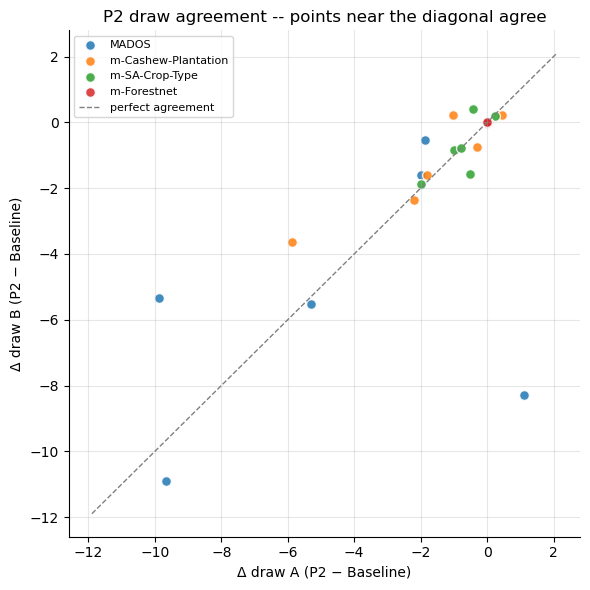

In [8]:
base_lookup = df_baseline.groupby(["encoder", "dataset"])["metric"].max()

agree_rows = []
for (enc, ds), sub in df_p2_draws.groupby(["encoder", "dataset"]):
    base_val = base_lookup.get((enc, ds))
    if base_val is None:
        continue
    val_a = sub.loc[sub["draw"] == "A", "metric"]
    val_b = sub.loc[sub["draw"] == "B", "metric"]
    if val_a.empty or val_b.empty:
        continue
    d_a = val_a.iloc[0] - base_val
    d_b = val_b.iloc[0] - base_val
    disagreement = abs(d_a - d_b)
    denom = max(abs(d_a), abs(d_b), 1e-6)
    sign_flip = (d_a > 0) != (d_b > 0) and denom > 0.5  # opposite sign and not both ~0
    flag = "⚠️" if (disagreement / denom > 0.6 or sign_flip) else "✅"
    agree_rows.append(dict(dataset=ds, encoder=enc, delta_draw_A=round(d_a, 3), delta_draw_B=round(d_b, 3),
                            abs_disagreement=round(disagreement, 3), flag=flag))

df_agree_p2 = pd.DataFrame(agree_rows).sort_values(["dataset", "abs_disagreement"], ascending=[True, False])
display(df_agree_p2)

n_flagged = (df_agree_p2["flag"] == "⚠️").sum()
print(f"\n{n_flagged}/{len(df_agree_p2)} encoder x dataset combos show notable P2 draw disagreement.")

fig, ax = plt.subplots(figsize=(6, 6))
for ds in DATASET_ORDER:
    sub = df_agree_p2[df_agree_p2["dataset"] == ds]
    ax.scatter(sub["delta_draw_A"], sub["delta_draw_B"], label=ds, s=50, alpha=0.85, edgecolor="white")
lims = [df_agree_p2[["delta_draw_A", "delta_draw_B"]].min().min() - 1,
        df_agree_p2[["delta_draw_A", "delta_draw_B"]].max().max() + 1]
ax.plot(lims, lims, "--", color="gray", linewidth=1, label="perfect agreement")
ax.set_xlabel("Δ draw A (P2 − Baseline)")
ax.set_ylabel("Δ draw B (P2 − Baseline)")
ax.set_title("P2 draw agreement -- points near the diagonal agree")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figures/p2_draw_agreement.png", bbox_inches="tight", dpi=150)
plt.show()

In [9]:
# ── P2 summary: mean of the two draws, used as the headline P2 condition ────

df_p2 = df_p2_draws.groupby(["encoder", "dataset"], as_index=False)["metric"].mean()
df_p2["condition"] = "P2 (mean of 2 draws)"
df_p2["run_dir"] = "mean(drawA, drawB)"

print(f"{len(df_p2)} P2 (mean) results")
df_p2.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

24 P2 (mean) results


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL,41.651,56.970,0.468,31.546
Copernicus-FM,53.295,68.187,0.522,32.114
DOFA,58.603,67.234,0.564,31.661
DOFA+,47.392,64.791,0.516,28.870
Panopticon,62.798,72.654,0.556,35.174
SMARTIES,54.678,68.784,0.500,32.914


## P3 -- full deterministic reversal

In [10]:
# ── P3 (deterministic full-vector reversal, no seeds) ───────────────────────

def load_p3() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "p3_wlswap_ablation"
    for enc_key, (enc_label, _, _, _) in ENCODER_INFO.items():
        d = base / enc_key
        if not d.exists():
            continue
        for run_dir in sorted(d.iterdir()):
            if not run_dir.is_dir():
                continue
            for key, label in ALL_DS_KEYS:
                if key in run_dir.name:
                    val = parse_run(run_dir, label)
                    if val is not None:
                        rows.append(dict(encoder=enc_label, dataset=label, condition="P3 (full reversal)",
                                          metric=val, run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p3 = load_p3()
print(f"{len(df_p3)} P3 results loaded")
df_p3.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

24 P3 results loaded


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL,48.170,56.037,0.448,31.735
Copernicus-FM,52.915,67.786,0.525,31.661
DOFA,54.348,65.239,0.562,31.420
DOFA+,52.973,66.304,0.524,29.498
Panopticon,64.446,71.034,0.562,34.840
SMARTIES,62.265,68.453,0.478,33.221


## P4 -- full random shuffle (3 seeded draws)

In [11]:
# ── P4 (unconstrained full-vector random permutation, 3 seeded draws) ───────

def load_p4_draws() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "p4_wlswap_ablation"
    for enc_key, (enc_label, _, _, _) in ENCODER_INFO.items():
        for draw in ["1", "2", "3"]:
            d = base / f"{enc_key}_draw{draw}"
            if not d.exists():
                continue
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in ALL_DS_KEYS:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, draw=draw,
                                              metric=val, run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p4_draws = load_p4_draws()
print(f"{len(df_p4_draws)} P4 per-draw results loaded ("
      + ", ".join(f"draw {d}: {(df_p4_draws['draw'] == d).sum()}" for d in ["1", "2", "3"]) + ")")
df_p4_draws.pivot_table(index=["encoder", "dataset"], columns="draw", values="metric", aggfunc="max").round(3)

72 P4 per-draw results loaded (draw 1: 24, draw 2: 24, draw 3: 24)


draw                                    1       2       3
encoder       dataset                                    
CARL          MADOS                43.844  46.818  42.914
              m-Cashew-Plantation  54.984  54.372  55.732
              m-Forestnet           0.444   0.432   0.444
              m-SA-Crop-Type       30.532  31.050  30.517
Copernicus-FM MADOS                52.501  52.844  47.243
              m-Cashew-Plantation  67.396  67.213  67.621
              m-Forestnet           0.517   0.506   0.512
              m-SA-Crop-Type       31.728  31.806  31.401
DOFA          MADOS                54.383  52.274  59.330
              m-Cashew-Plantation  66.314  66.645  64.096
              m-Forestnet           0.556   0.544   0.529
              m-SA-Crop-Type       30.912  31.419  30.800
DOFA+         MADOS                47.587  50.011  45.702
              m-Cashew-Plantation  66.515  65.831  66.985
              m-Forestnet           0.528   0.503   0.495
              m-SA-Crop-Type       28.983  29.364  29.565
Panopticon    MADOS                68.038  61.924  56.546
              m-Cashew-Plantation  69.797  70.044  71.323
              m-Forestnet           0.541   0.557   0.554
              m-SA-Crop-Type       33.222  33.714  33.571
SMARTIES      MADOS                58.808  59.462  56.633
              m-Cashew-Plantation  68.098  67.807  69.182
              m-Forestnet           0.498   0.479   0.474
              m-SA-Crop-Type       31.658  32.270  32.170

### What actually got shuffled in the three P4 draws

Same slope-chart idea as the P2 diagram (left = native/correct wavelength, right = reassigned label), but
now lines are colored by the *origin* band's spectral group purely for reference -- P4 respects no group
boundary, so unlike P2's diagram (where every line stayed within its color) you should see lines freely
crossing from VIS all the way to SWIR and back. That cross-group chaos is the whole point of P4 vs. P2.
No band is held fixed here (full shuffle touches every band, including B9 and m-Forestnet's NIR, which P1/P2/P3
all left untouched). Source: `scripts/slurm_scripts/wavelength_ablation/p4_wlswap_draws.json`.

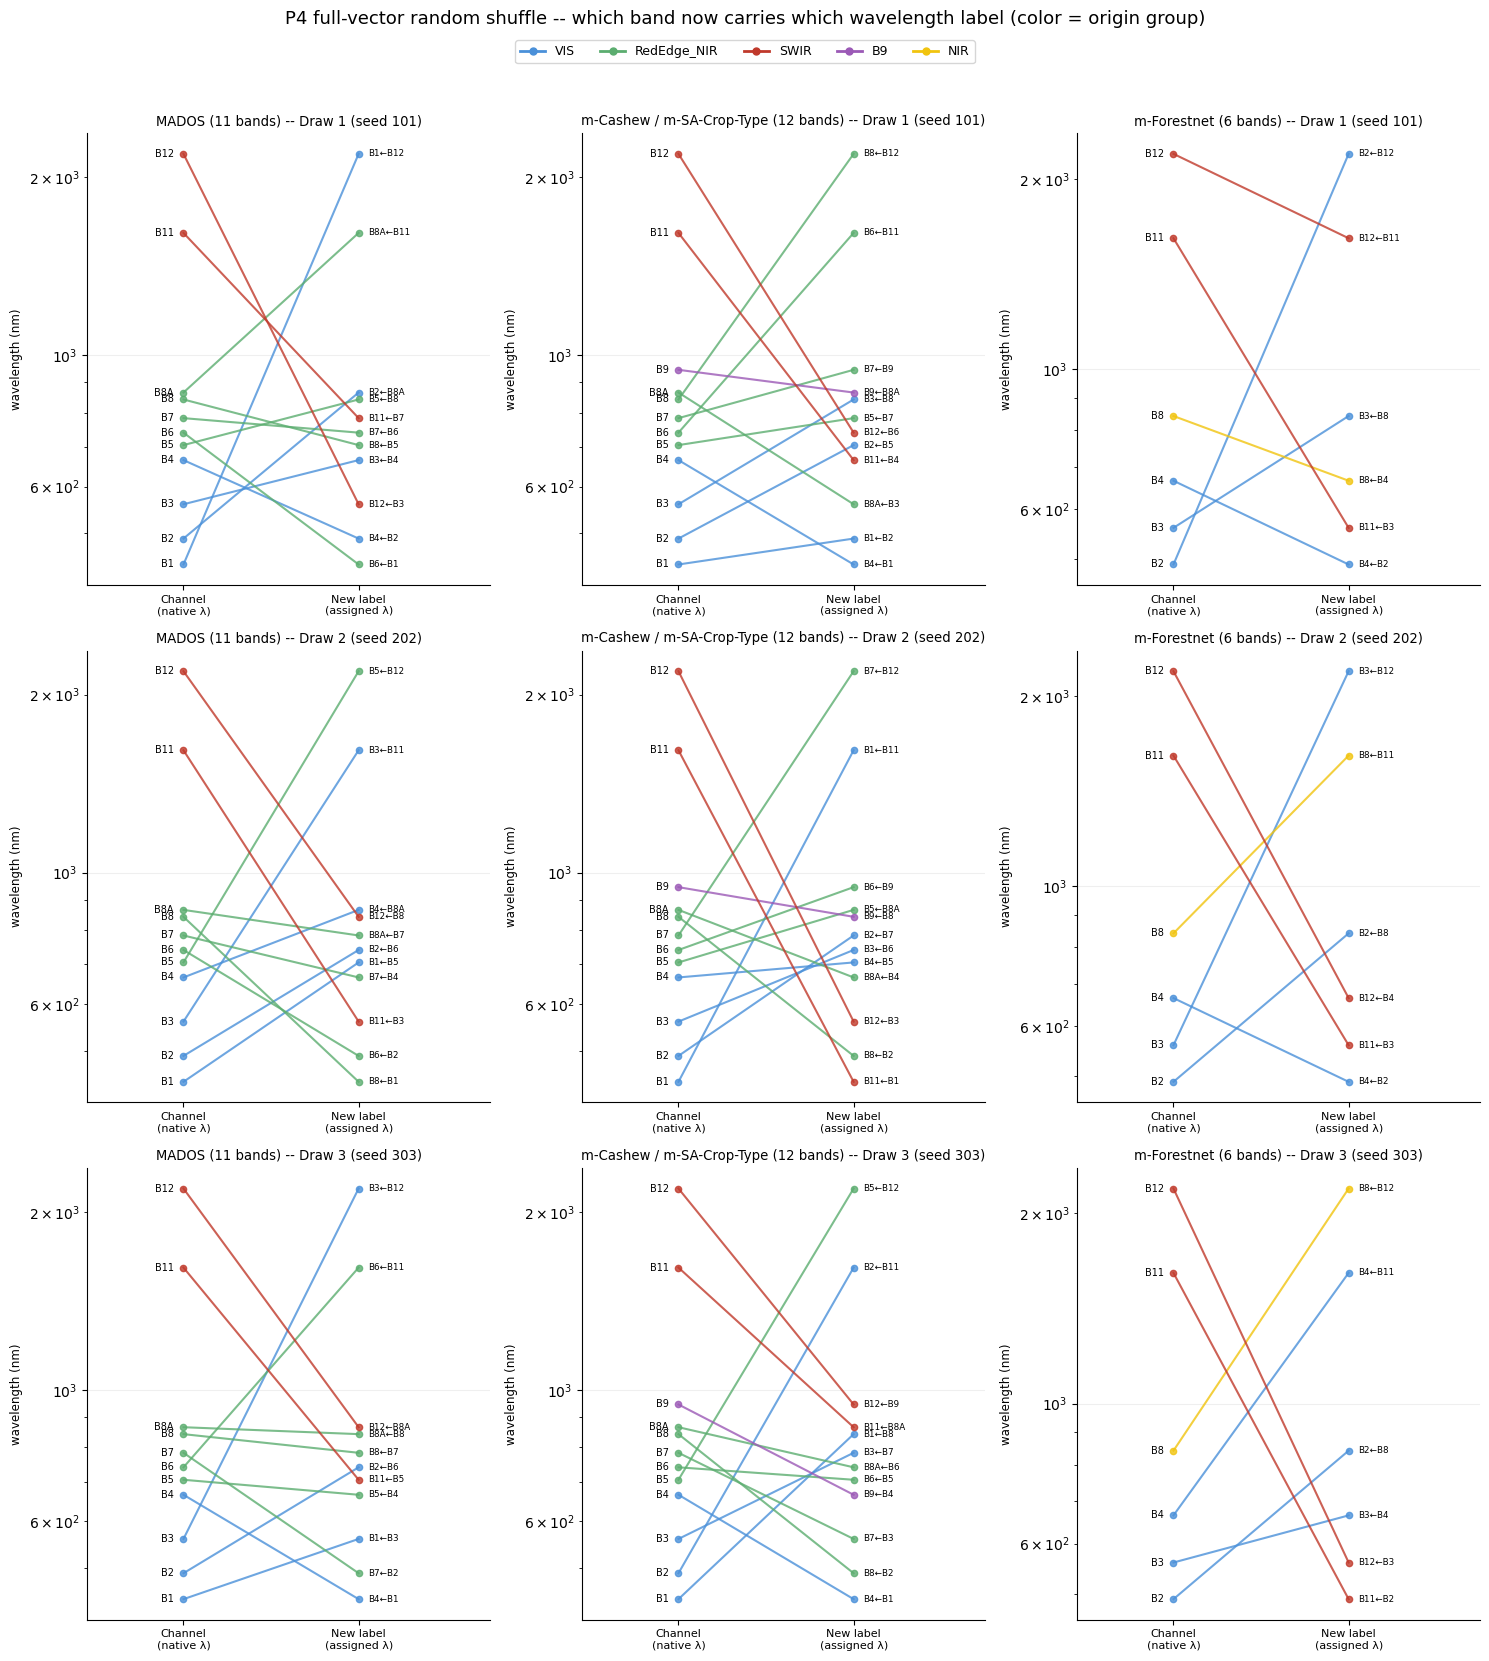

In [12]:
with open("../../scripts/slurm_scripts/wavelength_ablation/p4_wlswap_draws.json") as f:
    p4_manifest = _json.load(f)

# Reuse REF_WL_NM from the P2 diagram cell above; extend the group-color convention with two
# more entries P2 never needed (B9 is left untouched by P1/P2/P3; m-Forestnet's NIR too).
P4_GROUP_COLORS = dict(GROUP_COLORS)
P4_GROUP_COLORS["B9"] = "#9B59B6"
P4_GROUP_COLORS["NIR"] = "#F1C40F"

S2_BAND_GROUP = {
    "B1": "VIS", "B2": "VIS", "B3": "VIS", "B4": "VIS",
    "B5": "RedEdge_NIR", "B6": "RedEdge_NIR", "B7": "RedEdge_NIR", "B8": "RedEdge_NIR", "B8A": "RedEdge_NIR",
    "B9": "B9",
    "B11": "SWIR", "B12": "SWIR",
}
MFN_BAND_GROUP = {
    "B2": "mForestnet_RGB", "B3": "mForestnet_RGB", "B4": "mForestnet_RGB",
    "B8": "NIR",
    "B11": "SWIR", "B12": "SWIR",
}
DSGROUP_LABELS = {
    "mados": "MADOS (11 bands)",
    "s2_12b": "m-Cashew / m-SA-Crop-Type (12 bands)",
    "mfn": "m-Forestnet (6 bands)",
}
DSGROUP_BAND_GROUPS = {"mados": S2_BAND_GROUP, "s2_12b": S2_BAND_GROUP, "mfn": MFN_BAND_GROUP}


def plot_p4_permutation_panel(ax, dsgroup: str, draw: str, title: str):
    mapping = p4_manifest["mapping"][draw][dsgroup]
    band_group = DSGROUP_BAND_GROUPS[dsgroup]
    order = p4_manifest["dataset_vectors"][dsgroup]["bands"]

    for band in order:
        source = mapping[band]
        y0, y1 = REF_WL_NM[band], REF_WL_NM[source]
        color = P4_GROUP_COLORS[band_group[band]]
        ax.plot([0, 1], [y0, y1], color=color, alpha=0.8, linewidth=1.5, marker="o", markersize=4.5, zorder=3)
        ax.annotate(band, (0, y0), textcoords="offset points", xytext=(-7, 0), ha="right", va="center", fontsize=7)
        ax.annotate(f"{band}←{source}", (1, y1), textcoords="offset points", xytext=(7, 0),
                     ha="left", va="center", fontsize=6.3)

    ax.set_yscale("log")
    ax.set_xlim(-0.55, 1.75)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Channel\n(native λ)", "New label\n(assigned λ)"], fontsize=8)
    ax.set_ylabel("wavelength (nm)", fontsize=8.5)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(3, 3, figsize=(15, 16))
for row, draw in enumerate(["1", "2", "3"]):
    seed = p4_manifest["seeds"][draw]
    for col, dsgroup in enumerate(["mados", "s2_12b", "mfn"]):
        plot_p4_permutation_panel(
            axes[row, col], dsgroup, draw,
            f"{DSGROUP_LABELS[dsgroup]} -- Draw {draw} (seed {seed})",
        )

legend_handles = [plt.Line2D([0], [0], color=c, lw=2, marker="o", markersize=5, label=g)
                  for g, c in P4_GROUP_COLORS.items() if g != "mForestnet_RGB"]
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=6, fontsize=9)

fig.suptitle("P4 full-vector random shuffle -- which band now carries which wavelength label (color = origin group)",
             fontsize=13, y=1.035)
fig.tight_layout()
fig.savefig("figures/p4_permutation_diagram.png", bbox_inches="tight", dpi=150)
fig.savefig("figures/p4_permutation_diagram.pdf", bbox_inches="tight")
plt.show()

### P4 draw spread

Three independent draws of an unconstrained random full-vector permutation. Dots are each draw's Δ vs.
baseline; the black dash is their mean (the value used everywhere else in this notebook as
"P4 (mean of 3 draws)"). Wide vertical spread for a given encoder means that draw-to-draw variability
dominates over the "full random shuffle" severity signal for that encoder/dataset -- read it with caution,
same caveat as the P2 draw-agreement check.

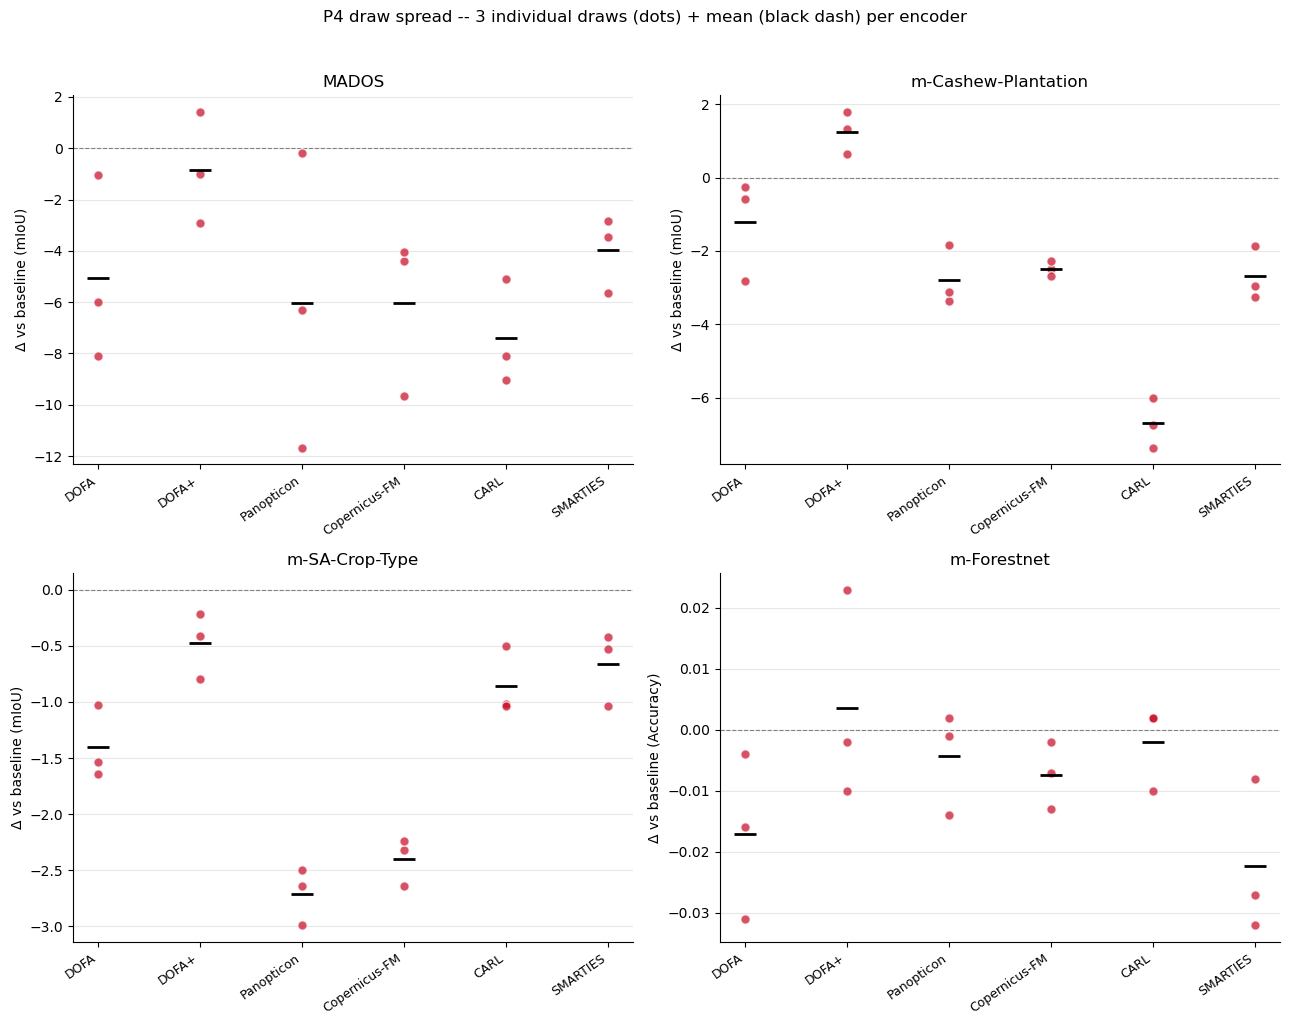

,dataset,encoder,mean_delta,range_delta,n_draws,flag
2,MADOS,Panopticon,-6.048,11.492,3,⚠️
0,MADOS,DOFA,-5.060,7.056,3,⚠️
3,MADOS,Copernicus-FM,-6.034,5.601,3,⚠️
1,MADOS,DOFA+,-0.835,4.309,3,⚠️
4,MADOS,CARL,-7.406,3.904,3,✅
5,MADOS,SMARTIES,-3.981,2.829,3,⚠️
6,m-Cashew-Plantation,DOFA,-1.218,2.549,3,⚠️
8,m-Cashew-Plantation,Panopticon,-2.782,1.526,3,✅
11,m-Cashew-Plantation,SMARTIES,-2.694,1.375,3,✅
10,m-Cashew-Plantation,CARL,-6.702,1.360,3,✅



16/24 combos show notable P4 draw spread.


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
p4_color = COND_COLORS["P4 (mean of 3 draws)"]

spread_rows = []
for ax, ds in zip(axes.flat, DATASET_ORDER):
    sub = df_p4_draws[df_p4_draws["dataset"] == ds]
    enc_present = [e for e in ENCODER_ORDER if e in sub["encoder"].unique()]
    for i, enc in enumerate(enc_present):
        esub = sub[sub["encoder"] == enc]
        base_val = base_lookup.get((enc, ds))
        if base_val is None or esub.empty:
            continue
        deltas = (esub["metric"] - base_val).values
        ax.scatter([i] * len(deltas), deltas, color=p4_color, alpha=0.7, s=45, zorder=3, edgecolor="white")
        ax.scatter([i], [deltas.mean()], color="black", marker="_", s=260, linewidths=2, zorder=4)
        spread_rows.append(dict(dataset=ds, encoder=enc, mean_delta=round(deltas.mean(), 3),
                                 range_delta=round(deltas.max() - deltas.min(), 3),
                                 n_draws=len(deltas)))

    ax.set_xticks(range(len(enc_present)))
    ax.set_xticklabels(enc_present, rotation=35, ha="right", fontsize=9)
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.set_ylabel(f"Δ vs baseline ({METRIC_LABELS[ds]})")
    ax.set_title(ds)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("P4 draw spread -- 3 individual draws (dots) + mean (black dash) per encoder", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig("figures/p4_draw_spread.png", bbox_inches="tight", dpi=150)
plt.show()

df_spread_p4 = pd.DataFrame(spread_rows).sort_values(["dataset", "range_delta"], ascending=[True, False])
denom = df_spread_p4["mean_delta"].abs().clip(lower=1e-6)
df_spread_p4["flag"] = np.where(df_spread_p4["range_delta"] / denom > 0.6, "⚠️", "✅")
display(df_spread_p4)
n_flagged_p4 = (df_spread_p4["flag"] == "⚠️").sum()
print(f"\n{n_flagged_p4}/{len(df_spread_p4)} combos show notable P4 draw spread.")

In [14]:
# ── P4 summary: mean of the three draws, used as the headline P4 condition ──

df_p4 = df_p4_draws.groupby(["encoder", "dataset"], as_index=False)["metric"].mean()
df_p4["condition"] = "P4 (mean of 3 draws)"
df_p4["run_dir"] = "mean(draw1, draw2, draw3)"

print(f"{len(df_p4)} P4 (mean) results")
df_p4.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

24 P4 (mean) results


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL,44.525,55.029,0.440,30.700
Copernicus-FM,50.863,67.410,0.512,31.645
DOFA,55.329,65.685,0.543,31.044
DOFA+,47.767,66.444,0.509,29.304
Panopticon,62.169,70.388,0.551,33.502
SMARTIES,58.301,68.362,0.484,32.033


In [15]:
# ── Combine + coverage check ─────────────────────────────────────────────────

df_all = pd.concat([df_baseline, df_p1, df_p2, df_p3, df_p4, df_const_wl], ignore_index=True)

expected = {(e, d) for e in ENCODER_ORDER for d in DATASET_ORDER}
for cond, df in [("Baseline (S2)", df_baseline), ("P1 (neighbor swap)", df_p1),
                  ("P2 (mean of 2 draws)", df_p2), ("P3 (full reversal)", df_p3),
                  ("P4 (mean of 3 draws)", df_p4), ("Const-WL (550nm)", df_const_wl)]:
    present = set(df[["encoder", "dataset"]].itertuples(index=False, name=None))
    missing = expected - present
    status = "complete" if not missing else f"MISSING: {sorted(missing)}"
    print(f"{cond:<24} {len(present)}/{len(expected)} combos -- {status}")

Baseline (S2)            24/24 combos -- complete
P1 (neighbor swap)       24/24 combos -- complete
P2 (mean of 2 draws)     24/24 combos -- complete
P3 (full reversal)       24/24 combos -- complete
P4 (mean of 3 draws)     24/24 combos -- complete
Const-WL (550nm)         24/24 combos -- complete


## Comparison tables -- Baseline vs. P1 vs. P2 vs. P3 vs. P4 vs. Const-WL

For each dataset: metric per condition, plus Δ (condition − Baseline), ordered by increasing severity.

In [16]:
SHORT_NAMES = {
    "P1 (neighbor swap)": "P1", "P2 (mean of 2 draws)": "P2", "P3 (full reversal)": "P3",
    "P4 (mean of 3 draws)": "P4", "Const-WL (550nm)": "Const-WL",
}


def make_comparison_table(df: pd.DataFrame, dataset: str, metric_label: str):
    sub = df[df["dataset"] == dataset]
    if sub.empty:
        print(f"  No data for {dataset}")
        return None
    pivot = sub.pivot_table(index="encoder", columns="condition", values="metric", aggfunc="max")
    col_order = [c for c in CONDITION_ORDER if c in pivot.columns]
    pivot = pivot[col_order].copy()
    if "Baseline (S2)" in pivot.columns:
        for cond in PERTURBATIONS:
            if cond in pivot.columns:
                pivot[f"Δ {SHORT_NAMES[cond]}"] = (pivot[cond] - pivot["Baseline (S2)"]).round(3)
    order = [e for e in ENCODER_ORDER if e in pivot.index]
    pivot = pivot.reindex(order).round(3)
    pivot.columns.name = f"{dataset}  [{metric_label}]"
    return pivot


for ds in DATASET_ORDER:
    t = make_comparison_table(df_all, ds, METRIC_LABELS[ds])
    if t is not None:
        display(t)

MADOS [mIoU],Baseline (S2),P1 (neighbor swap),P2 (mean of 2 draws),P3 (full reversal),P4 (mean of 3 draws),Const-WL (550nm),Δ P1,Δ P2,Δ P3,Δ P4,Δ Const-WL
encoder,,,,,,,,,,,
DOFA,60.389,61.090,58.603,54.348,55.329,33.084,0.701,-1.786,-6.041,-5.060,-27.305
DOFA+,48.602,46.144,47.392,52.973,47.767,38.363,-2.458,-1.209,4.371,-0.835,-10.239
Panopticon,68.217,66.589,62.798,64.446,62.169,44.884,-1.628,-5.419,-3.771,-6.048,-23.333
Copernicus-FM,56.897,57.811,53.295,52.915,50.863,42.635,0.914,-3.602,-3.982,-6.034,-14.262
CARL,51.931,47.134,41.651,48.170,44.525,32.553,-4.797,-10.280,-3.761,-7.406,-19.378
SMARTIES,62.282,61.563,54.678,62.265,58.301,25.005,-0.719,-7.603,-0.017,-3.981,-37.277


m-Cashew-Plantation [mIoU],Baseline (S2),P1 (neighbor swap),P2 (mean of 2 draws),P3 (full reversal),P4 (mean of 3 draws),Const-WL (550nm),Δ P1,Δ P2,Δ P3,Δ P4,Δ Const-WL
encoder,,,,,,,,,,,
DOFA,66.903,66.975,67.234,65.239,65.685,53.079,0.072,0.331,-1.664,-1.218,-13.824
DOFA+,65.200,64.792,64.791,66.304,66.444,59.216,-0.408,-0.409,1.104,1.244,-5.984
Panopticon,73.170,72.993,72.654,71.034,70.388,67.848,-0.177,-0.516,-2.136,-2.782,-5.322
Copernicus-FM,69.898,69.967,68.187,67.786,67.410,65.104,0.069,-1.711,-2.112,-2.488,-4.794
CARL,61.731,59.341,56.970,56.037,55.029,48.846,-2.390,-4.760,-5.694,-6.702,-12.885
SMARTIES,71.056,70.554,68.784,68.453,68.362,44.670,-0.502,-2.272,-2.603,-2.694,-26.386


m-SA-Crop-Type [mIoU],Baseline (S2),P1 (neighbor swap),P2 (mean of 2 draws),P3 (full reversal),P4 (mean of 3 draws),Const-WL (550nm),Δ P1,Δ P2,Δ P3,Δ P4,Δ Const-WL
encoder,,,,,,,,,,,
DOFA,32.444,32.540,31.661,31.420,31.044,20.565,0.096,-0.783,-1.024,-1.400,-11.879
DOFA+,29.780,29.792,28.870,29.498,29.304,23.189,0.012,-0.910,-0.282,-0.476,-6.591
Panopticon,36.210,36.082,35.174,34.840,33.502,27.949,-0.128,-1.035,-1.370,-2.708,-8.261
Copernicus-FM,34.043,33.055,32.114,31.661,31.645,29.584,-0.988,-1.929,-2.382,-2.398,-4.459
CARL,31.555,32.490,31.546,31.735,30.700,23.486,0.935,-0.008,0.180,-0.855,-8.069
SMARTIES,32.695,33.032,32.914,33.221,32.033,18.576,0.337,0.219,0.526,-0.662,-14.119


m-Forestnet [Accuracy],Baseline (S2),P1 (neighbor swap),P2 (mean of 2 draws),P3 (full reversal),P4 (mean of 3 draws),Const-WL (550nm),Δ P1,Δ P2,Δ P3,Δ P4,Δ Const-WL
encoder,,,,,,,,,,,
DOFA,0.560,0.555,0.564,0.562,0.543,0.524,-0.005,0.004,0.002,-0.017,-0.036
DOFA+,0.505,0.516,0.516,0.524,0.509,0.489,0.011,0.011,0.019,0.004,-0.016
Panopticon,0.555,0.554,0.556,0.562,0.551,0.540,-0.001,0.001,0.007,-0.004,-0.015
Copernicus-FM,0.519,0.522,0.522,0.525,0.512,0.512,0.003,0.003,0.006,-0.007,-0.007
CARL,0.442,0.473,0.468,0.448,0.440,0.403,0.031,0.027,0.006,-0.002,-0.039
SMARTIES,0.506,0.491,0.500,0.478,0.484,0.414,-0.015,-0.006,-0.028,-0.022,-0.092


## Delta heatmaps -- same colorscale across all four perturbations

All four heatmaps share one colorscale (set by the largest magnitude, normally Const-WL) so severity is directly comparable left-to-right.

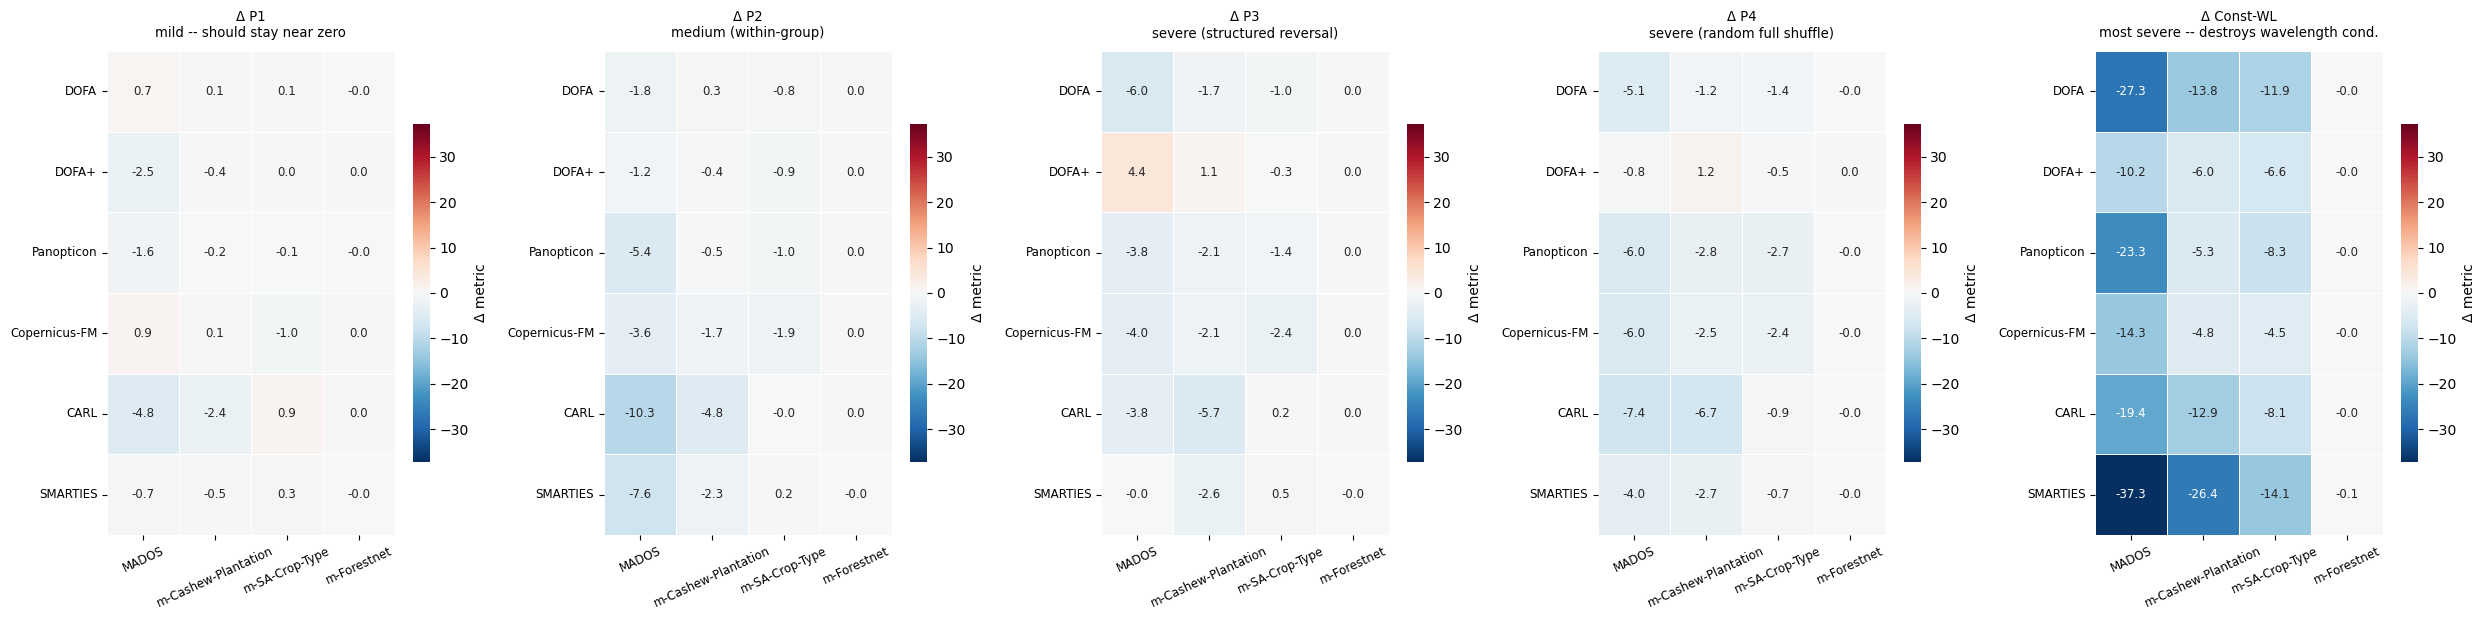

In [17]:
base_pivot = df_baseline.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max")

pivots = {cond: df_all[df_all["condition"] == cond].pivot_table(
    index="encoder", columns="dataset", values="metric", aggfunc="max") for cond in PERTURBATIONS}


def delta_of(pivot):
    _, aligned = base_pivot.align(pivot, join="outer")
    return (aligned - base_pivot).reindex(
        index=[e for e in ENCODER_ORDER if e in base_pivot.index],
        columns=[d for d in DATASET_ORDER if d in base_pivot.columns],
    )


deltas = {cond: delta_of(pivots[cond]) for cond in PERTURBATIONS}
vmax = max(1.0, *(float(d.abs().max().max()) for d in deltas.values()))

fig, axes = plt.subplots(1, len(PERTURBATIONS), figsize=(len(DATASET_ORDER) * 2.2 * len(PERTURBATIONS) / 2 + 3, len(ENCODER_ORDER) * 0.65 + 2.4))

titles = {
    "P1 (neighbor swap)":   "Δ P1\nmild -- should stay near zero",
    "P2 (mean of 2 draws)": "Δ P2\nmedium (within-group)",
    "P3 (full reversal)":   "Δ P3\nsevere (structured reversal)",
    "P4 (mean of 3 draws)": "Δ P4\nsevere (random full shuffle)",
    "Const-WL (550nm)":     "Δ Const-WL\nmost severe -- destroys wavelength cond.",
}

for ax, cond in zip(axes, PERTURBATIONS):
    sns.heatmap(
        deltas[cond], ax=ax, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
        annot=True, fmt=".1f", annot_kws={"size": 8.5},
        linewidths=0.5, linecolor="white",
        cbar_kws={"label": "Δ metric", "shrink": 0.7},
    )
    ax.set_title(titles[cond], fontsize=9.5, pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25, labelsize=8.5)
    ax.tick_params(axis="y", rotation=0, labelsize=8.5)

fig.tight_layout()
fig.savefig("figures/full_ladder_delta_heatmaps.pdf", bbox_inches="tight")
fig.savefig("figures/full_ladder_delta_heatmaps.png", bbox_inches="tight", dpi=150)
plt.show()

## Grouped bar chart -- Baseline / P1 / P2 / P3 / P4 / Const-WL per encoder x dataset

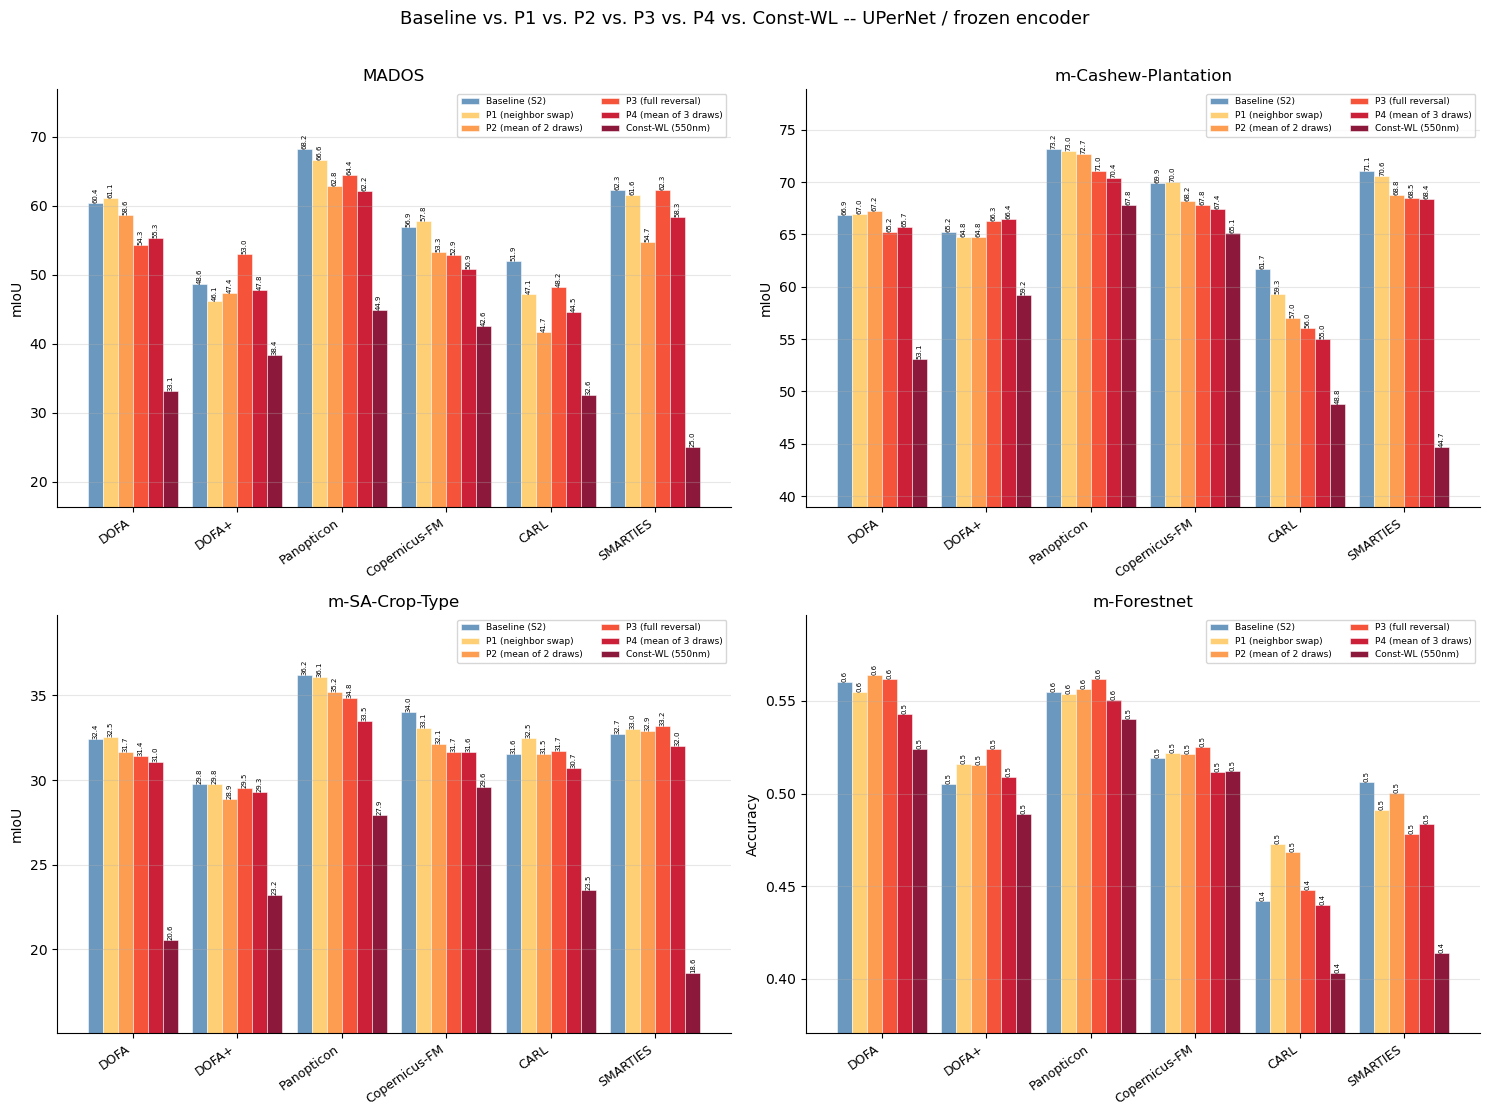

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharey=False)

for ax, ds in zip(axes.flat, DATASET_ORDER):
    sub = df_all[df_all["dataset"] == ds].copy()
    enc_present = [e for e in ENCODER_ORDER if e in sub["encoder"].unique()]
    sub = sub[sub["encoder"].isin(enc_present)]
    sub = sub.groupby(["encoder", "condition"], as_index=False)["metric"].max()

    x = np.arange(len(enc_present))
    n_cond = len(CONDITION_ORDER)
    width = 0.86 / n_cond
    for i, cond in enumerate(CONDITION_ORDER):
        vals = [sub.loc[(sub["encoder"] == e) & (sub["condition"] == cond), "metric"].values for e in enc_present]
        heights = [v[0] if len(v) > 0 else np.nan for v in vals]
        bars = ax.bar(
            x + (i - (n_cond - 1) / 2) * width, heights, width,
            label=cond, color=COND_COLORS[cond], alpha=0.9,
            edgecolor="white", linewidth=0.4,
        )
        for bar, h in zip(bars, heights):
            if not np.isnan(h):
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{h:.1f}",
                        ha="center", va="bottom", fontsize=5, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(enc_present, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel(METRIC_LABELS[ds])
    ax.set_title(ds)
    ax.legend(fontsize=6.5, ncol=2)
    present_vals = sub["metric"].dropna()
    if len(present_vals):
        pad = (present_vals.max() - present_vals.min()) * 0.2 + 1e-6
        ax.set_ylim(bottom=max(0, present_vals.min() - pad), top=present_vals.max() + pad)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Baseline vs. P1 vs. P2 vs. P3 vs. P4 vs. Const-WL -- UPerNet / frozen encoder", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/full_ladder_bars.png", bbox_inches="tight", dpi=150)
plt.show()

## Severity-ladder check

Two checks against the physically-grounded hypothesis:
1. **Sanity floor**: `|Δ P1|` should be a small fraction of `|Δ Const-WL|` (flagged ⚠️ above 25%).
2. **Monotonicity**: damage should scale with severity along `P1 -> P2 -> {P3, P4} -> Const-WL`
   (with tolerance for run-to-run noise). Since P3 and P4 aren't expected to have a fixed order relative to
   each other, each is checked independently against its neighbors (`|ΔP2| <= |ΔP3|` and `|ΔP2| <= |ΔP4|`,
   both `<= |Δ Const-WL|`) rather than forcing one linear chain through both.

In [19]:
TOL = 1.0  # tolerance (metric points / accuracy*100-equivalent) before flagging a monotonicity violation

rows = []
for ds in DATASET_ORDER:
    for enc in ENCODER_ORDER:
        try:
            d = {cond: deltas[cond].loc[enc, ds] for cond in PERTURBATIONS}
        except KeyError:
            continue
        if any(pd.isna(v) for v in d.values()):
            continue

        tol = TOL / 100 if METRIC_LABELS[ds] == "Accuracy" else TOL
        abs_d = {k: abs(v) for k, v in d.items()}

        ratio_p1 = abs_d["P1 (neighbor swap)"] / abs_d["Const-WL (550nm)"] if abs_d["Const-WL (550nm)"] > 1e-6 else np.nan
        sanity_flag = "⚠️" if (not np.isnan(ratio_p1) and ratio_p1 > 0.25) else "✅"

        checks = [
            abs_d["P1 (neighbor swap)"] <= abs_d["P2 (mean of 2 draws)"] + tol,
            abs_d["P2 (mean of 2 draws)"] <= abs_d["P3 (full reversal)"] + tol,
            abs_d["P2 (mean of 2 draws)"] <= abs_d["P4 (mean of 3 draws)"] + tol,
            abs_d["P3 (full reversal)"] <= abs_d["Const-WL (550nm)"] + tol,
            abs_d["P4 (mean of 3 draws)"] <= abs_d["Const-WL (550nm)"] + tol,
        ]
        mono_flag = "✅" if all(checks) else "⚠️"

        rows.append(dict(dataset=ds, encoder=enc,
                          delta_p1=round(d["P1 (neighbor swap)"], 3), delta_p2=round(d["P2 (mean of 2 draws)"], 3),
                          delta_p3=round(d["P3 (full reversal)"], 3), delta_p4=round(d["P4 (mean of 3 draws)"], 3),
                          delta_const_wl=round(d["Const-WL (550nm)"], 3),
                          sanity_floor=sanity_flag, monotonic=mono_flag))

df_ladder = pd.DataFrame(rows).sort_values(["dataset", "encoder"])
display(df_ladder)

n_sanity = (df_ladder["sanity_floor"] == "⚠️").sum()
n_mono = (df_ladder["monotonic"] == "⚠️").sum()
print(f"\n{n_sanity}/{len(df_ladder)} combos flagged on sanity floor (|Δ P1| > 25% of |Δ Const-WL|).")
print(f"{n_mono}/{len(df_ladder)} combos flagged on monotonicity (severity ordering violated beyond tolerance).")

,dataset,encoder,delta_p1,delta_p2,delta_p3,delta_p4,delta_const_wl,sanity_floor,monotonic
4,MADOS,CARL,-4.797,-10.280,-3.761,-7.406,-19.378,✅,⚠️
3,MADOS,Copernicus-FM,0.914,-3.602,-3.982,-6.034,-14.262,✅,✅
0,MADOS,DOFA,0.701,-1.786,-6.041,-5.060,-27.305,✅,✅
1,MADOS,DOFA+,-2.458,-1.209,4.371,-0.835,-10.239,✅,⚠️
2,MADOS,Panopticon,-1.628,-5.419,-3.771,-6.048,-23.333,✅,⚠️
5,MADOS,SMARTIES,-0.719,-7.603,-0.017,-3.981,-37.277,✅,⚠️
10,m-Cashew-Plantation,CARL,-2.390,-4.760,-5.694,-6.702,-12.885,✅,✅
9,m-Cashew-Plantation,Copernicus-FM,0.069,-1.711,-2.112,-2.488,-4.794,✅,✅
6,m-Cashew-Plantation,DOFA,0.072,0.331,-1.664,-1.218,-13.824,✅,✅
7,m-Cashew-Plantation,DOFA+,-0.408,-0.409,1.104,1.244,-5.984,✅,✅



3/24 combos flagged on sanity floor (|Δ P1| > 25% of |Δ Const-WL|).
5/24 combos flagged on monotonicity (severity ordering violated beyond tolerance).
